# Plot the results of the learnable parameter sweep
The purpose of this notebook is to plot the testing accuracies and learned gamma trajectories as a function of epoch for each task label condition.

## Imports

In [1]:
import json
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

## Extract data from JSON

In [2]:
def load_results(json_path):
    """Load results from JSON file."""
    with open(json_path, 'r') as f:
        return json.load(f)

In [3]:
def extract_test_acc_trajectories(results, label_mode, init_gamma):
    """Extract test accuracy trajectories across seeds.

    Args:
        results: nested dict from sweep
        label_mode: 'feature', 'position', or 'both'
        init_gamma: initial gamma value

    Returns:
        np.array of shape (num_seeds, num_epochs) with test accuracies
    """
    gamma_key = str(float(init_gamma))
    seed_data = results[label_mode][gamma_key]

    trajectories = []
    for seed in sorted(seed_data.keys()):
        history = seed_data[seed]

        if label_mode == 'both':
            # Average feature and position accuracy
            test_acc_f = np.array(history['test_acc_f'])
            test_acc_p = np.array(history['test_acc_p'])
            test_acc = (test_acc_f + test_acc_p) / 2.0
        else:
            test_acc = np.array(history['test_acc'])

        trajectories.append(test_acc)

    return np.array(trajectories)

## Plot testing accuracies

In [4]:
def extract_test_acc_trajectories(results, label_mode, init_gamma):
    """Extract test accuracy trajectories across seeds.

    Args:
        results: nested dict from sweep
        label_mode: 'feature', 'position', or 'both'
        init_gamma: initial gamma value

    Returns:
        np.array of shape (num_seeds, num_epochs) with test accuracies
    """
    gamma_key = str(float(init_gamma))
    seed_data = results[label_mode][gamma_key]

    trajectories = []
    for seed in sorted(seed_data.keys()):
        history = seed_data[seed]

        if label_mode == 'both':
            # Average feature and position accuracy
            test_acc_f = np.array(history['test_acc_f'])
            test_acc_p = np.array(history['test_acc_p'])
            test_acc = (test_acc_f + test_acc_p) / 2.0
        else:
            test_acc = np.array(history['test_acc'])

        trajectories.append(test_acc)

    return np.array(trajectories)


def plot_learnable_gamma_results(
    results_path='./data/learnable_gamma_sweep.json',
    save_path='./results/learnable_gamma_accuracy_curves.png',
):
    """Plot test accuracy vs epoch for all (label_mode, init_gamma) combinations.

    Creates a 3-panel plot (one per label mode) with 5 lines (one per init gamma)
    showing mean test accuracy across seeds with SEM shading.
    """
    results = load_results(results_path)

    label_modes = ['feature', 'position', 'both']
    init_gammas = [0.0, 0.25, 0.5, 0.75, 1.0]

    # Color map for init_gamma values
    cmap = plt.cm.plasma
    colors = [cmap(i / (len(init_gammas) - 1)) for i in range(len(init_gammas))]

    fig, axes = plt.subplots(1, 3, figsize=(12.5, 3))

    for ax_idx, label_mode in enumerate(label_modes):
        ax = axes[ax_idx]

        for i, init_gamma in enumerate(init_gammas):
            # Extract trajectories for this condition
            trajectories = extract_test_acc_trajectories(results, label_mode, init_gamma)

            # Compute mean and SEM across seeds
            mean_acc = trajectories.mean(axis=0)
            sem_acc = trajectories.std(axis=0) / np.sqrt(trajectories.shape[0])

            epochs = np.arange(len(mean_acc))

            # Plot mean line
            label = f"γ₀={init_gamma:.2f}"
            ax.plot(
                epochs,
                mean_acc,
                color=colors[i],
                label=label,
                linewidth=1.5,
                alpha=0.8,
            )

            # Shade SEM
            ax.fill_between(
                epochs,
                mean_acc - sem_acc,
                mean_acc + sem_acc,
                color=colors[i],
                alpha=0.15,
            )

        ax.set_xlabel('Epoch', fontsize=11)
        ax.set_ylabel('Test Accuracy', fontsize=11)
        ax.set_title(f'{label_mode.capitalize()}', fontsize=12, fontweight='bold')
        ax.grid(True, alpha=0.3)
        if label_mode != 'position':
            ax.legend(fontsize=9)

    fig.suptitle('Learnable γ: Test Accuracy Evolution', fontsize=14, fontweight='bold', y=0.95)
    plt.tight_layout()

    if save_path:
        Path(save_path).parent.mkdir(parents=True, exist_ok=True)
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"Saved to {save_path}")

    plt.show()

Saved to ../results/learnable_gamma_accuracy_curves.png


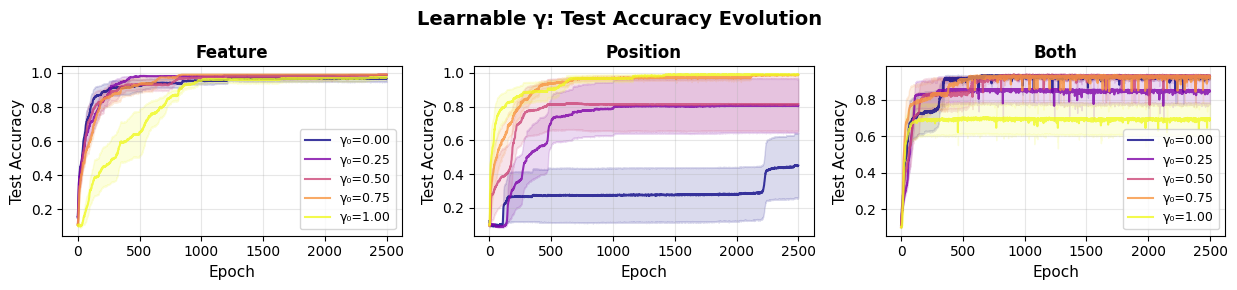

In [5]:
# Plot test accuracy curves
plot_learnable_gamma_results(
    results_path='../data/learnable_gamma_sweep.json',
    save_path='../results/learnable_gamma_accuracy_curves.png',
)

## Plot gamma trajectories

In [6]:
def plot_gamma_evolution(
    results_path='./data/learnable_gamma_sweep.json',
    save_path='./results/learnable_gamma_evolution.png',
):
    """Plot gamma value evolution during training.

    Shows how gamma changes from its initialization across training.
    Creates a 3-panel plot (one per label mode).
    """
    results = load_results(results_path)

    label_modes = ['feature', 'position', 'both']
    init_gammas = [0.0, 0.25, 0.5, 0.75, 1.0]

    # Color map
    cmap = plt.cm.plasma
    colors = [cmap(i / (len(init_gammas) - 1)) for i in range(len(init_gammas))]

    fig, axes = plt.subplots(1, 3, figsize=(12.5, 3))

    for ax_idx, label_mode in enumerate(label_modes):
        ax = axes[ax_idx]

        for i, init_gamma in enumerate(init_gammas):
            gamma_key = str(float(init_gamma))
            seed_data = results[label_mode][gamma_key]

            # Collect gamma trajectories
            gamma_trajectories = []
            for seed in sorted(seed_data.keys()):
                gamma_hist = np.array(seed_data[seed]['gamma'])
                gamma_trajectories.append(gamma_hist)

            gamma_trajectories = np.array(gamma_trajectories)
            mean_gamma = gamma_trajectories.mean(axis=0)
            sem_gamma = gamma_trajectories.std(axis=0) / np.sqrt(gamma_trajectories.shape[0])

            epochs = np.arange(len(mean_gamma))

            label = f"γ₀={init_gamma:.2f}"
            ax.plot(
                epochs,
                mean_gamma,
                color=colors[i],
                label=label,
                linewidth=1.5,
                alpha=0.8,
            )

            ax.fill_between(
                epochs,
                mean_gamma - sem_gamma,
                mean_gamma + sem_gamma,
                color=colors[i],
                alpha=0.15,
            )

        # Add reference lines at γ=0 and γ=1
        ax.axhline(0.0, color='gray', linestyle='--', alpha=0.3, linewidth=1)
        ax.axhline(1.0, color='gray', linestyle='--', alpha=0.3, linewidth=1)

        ax.set_xlabel('Epoch', fontsize=11)
        ax.set_ylabel('γ Value', fontsize=11)
        ax.set_title(f'{label_mode.capitalize()}', fontsize=12, fontweight='bold')
        ax.set_ylim(-0.05, 1.05)
        ax.grid(True, alpha=0.3)
        if label_mode != 'position':
            ax.legend(fontsize=9)

    fig.suptitle('Learnable γ: Parameter Evolution', fontsize=14, fontweight='bold', y=0.95)
    plt.tight_layout()

    if save_path:
        Path(save_path).parent.mkdir(parents=True, exist_ok=True)
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"Saved to {save_path}")

    plt.show()

Saved to ../results/learnable_gamma_evolution.png


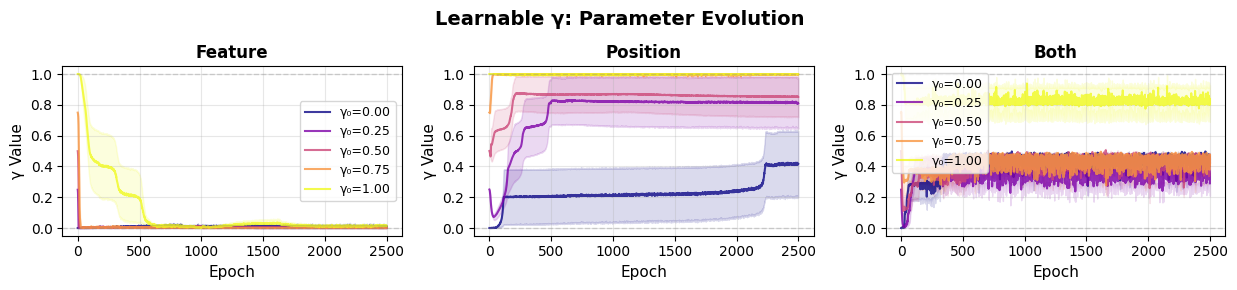

In [7]:
# Plot gamma evolution
plot_gamma_evolution(
    results_path='../data/learnable_gamma_sweep.json',
    save_path='../results/learnable_gamma_evolution.png',
)